In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub

path = kagglehub.dataset_download("khwaishsaxena/lung-cancer-dataset")
df = pd.read_csv(path + "/Lung Cancer.csv")

100%|██████████| 18.3M/18.3M [00:00<00:00, 64.2MB/s]

Extracting files...


In [ ]:
df.head()

,id,age,gender,country,diagnosis_date,cancer_stage,family_history,smoking_status,bmi,cholesterol_level,hypertension,asthma,cirrhosis,other_cancer,treatment_type,end_treatment_date,survived
0,1,64.0,Male,Sweden,2016-04-05,Stage I,Yes,Passive Smoker,29.4,199,0,0,1,0,Chemotherapy,2017-09-10,0
1,2,50.0,Female,Netherlands,2023-04-20,Stage III,Yes,Passive Smoker,41.2,280,1,1,0,0,Surgery,2024-06-17,1
2,3,65.0,Female,Hungary,2023-04-05,Stage III,Yes,Former Smoker,44.0,268,1,1,0,0,Combined,2024-04-09,0
3,4,51.0,Female,Belgium,2016-02-05,Stage I,No,Passive Smoker,43.0,241,1,1,0,0,Chemotherapy,2017-04-23,0
4,5,37.0,Male,Luxembourg,2023-11-29,Stage I,No,Passive Smoker,19.7,178,0,0,0,0,Combined,2025-01-08,0


# Data Cleaning

In [ ]:
df = df.drop("id", axis=1)
df['age'] = df['age'].astype('int')
df.head()

,age,gender,country,diagnosis_date,cancer_stage,family_history,smoking_status,bmi,cholesterol_level,hypertension,asthma,cirrhosis,other_cancer,treatment_type,end_treatment_date,survived
0,64,Male,Sweden,2016-04-05,Stage I,Yes,Passive Smoker,29.4,199,0,0,1,0,Chemotherapy,2017-09-10,0
1,50,Female,Netherlands,2023-04-20,Stage III,Yes,Passive Smoker,41.2,280,1,1,0,0,Surgery,2024-06-17,1
2,65,Female,Hungary,2023-04-05,Stage III,Yes,Former Smoker,44.0,268,1,1,0,0,Combined,2024-04-09,0
3,51,Female,Belgium,2016-02-05,Stage I,No,Passive Smoker,43.0,241,1,1,0,0,Chemotherapy,2017-04-23,0
4,37,Male,Luxembourg,2023-11-29,Stage I,No,Passive Smoker,19.7,178,0,0,0,0,Combined,2025-01-08,0


# Data Exploration

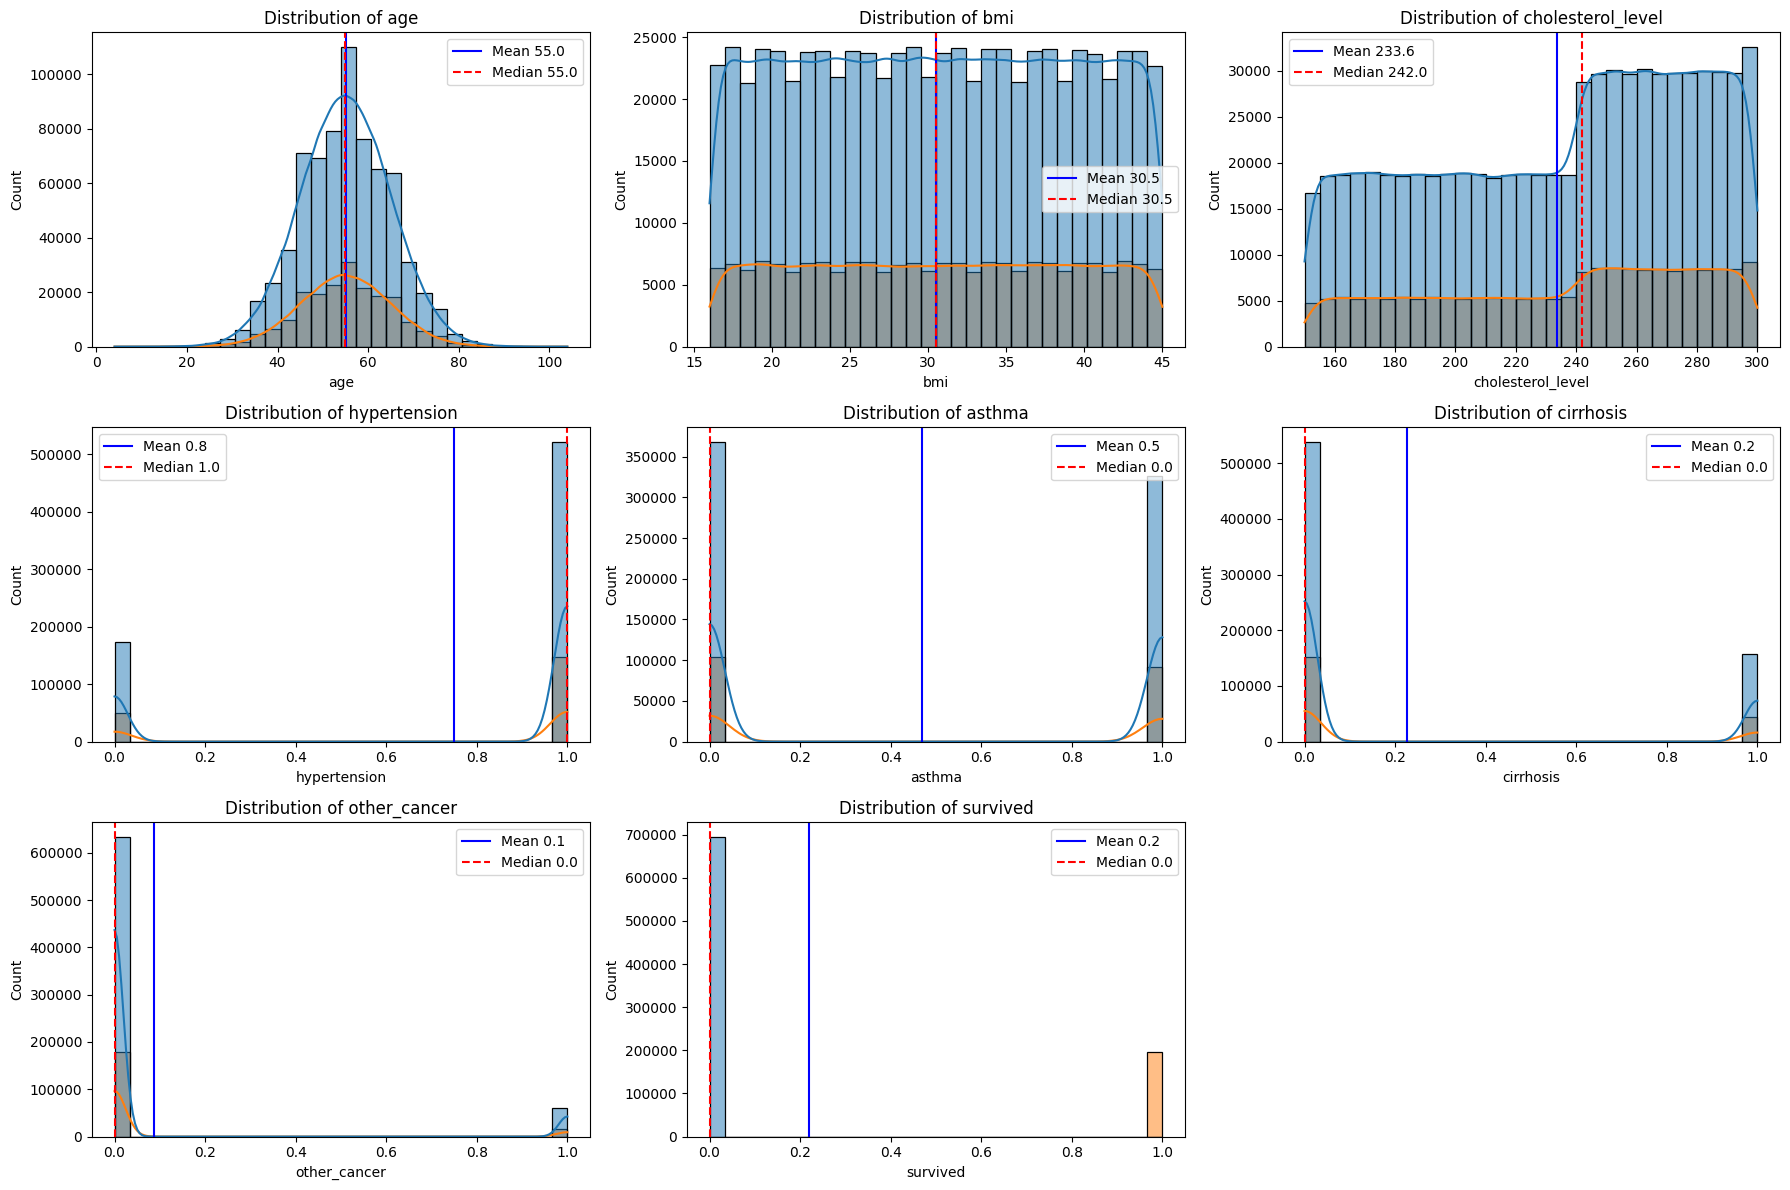

In [ ]:
n_cols = 3
cols = df.select_dtypes(include='number').columns

n_rows = (len(cols) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, n_rows * 4))

if n_rows == 1:
    axes = np.array(axes).reshape(-1)
else:
    axes = axes.flatten()

for i, col in enumerate(cols):
    sns.histplot(data=df, x=col, ax=axes[i], kde=True, bins=30, hue='survived')

    mean_val = df[col].mean()
    median_val = df[col].median()

    axes[i].axvline(mean_val, color='blue', linestyle='-', label=f'Mean {mean_val:.1f}')
    axes[i].axvline(median_val, color='red', linestyle='--', label=f'Median {median_val:.1f}')

    axes[i].set_title(f"Distribution of {col}")
    axes[i].legend()

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

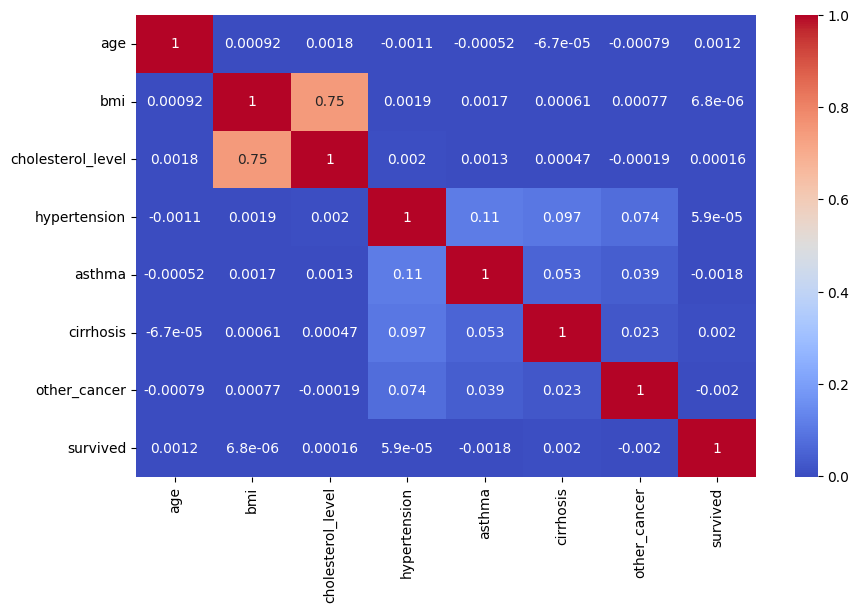

In [ ]:
plt.figure(figsize=(10, 6))
sns.heatmap(df.select_dtypes("number").corr(), annot=True, cmap='coolwarm')
plt.show()

# Feature Engineering

In [ ]:
df['treatment_duration'] = pd.to_datetime(df['end_treatment_date']) - pd.to_datetime(df['diagnosis_date'])
df['treatment_duration'] = df['treatment_duration'].dt.days

df = df.drop("diagnosis_date", axis=1)
df = df.drop("end_treatment_date", axis=1)

df.sample(10)

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

one_hot_col = ['gender', 'family_history']
ordinal_col = ['country', 'cancer_stage', 'smoking_status', 'treatment_type']

stage_order = ['Stage I', 'Stage II', 'Stage III', 'Stage IV']
smoking_order = ['Never Smoked', 'Passive Smoker', 'Former Smoker', 'Current Smoker']

country_order = sorted(df['country'].dropna().unique())
treatment_order = sorted(df['treatment_type'].dropna().unique())

ordinal_categories = [country_order, stage_order, smoking_order, treatment_order]

preprocessor = ColumnTransformer(
    transformers=[
        (
            'onehot',
            OneHotEncoder(sparse_output=False, handle_unknown='ignore'),
            one_hot_col
        ),
        (
            'ordinal',
            OrdinalEncoder(
                categories=ordinal_categories,
                handle_unknown='use_encoded_value',
                unknown_value=-1
            ),
            ordinal_col
        )
    ],
    remainder='passthrough',
    verbose_feature_names_out=False
)

preprocessor.set_output(transform="pandas")
df = preprocessor.fit_transform(df)

df.head()

,gender_Female,gender_Male,family_history_No,family_history_Yes,country,cancer_stage,smoking_status,treatment_type,age,bmi,cholesterol_level,hypertension,asthma,cirrhosis,other_cancer,survived,treatment_duration
0,0.0,1.0,0.0,1.0,26.0,0.0,1.0,0.0,64,29.4,199,0,0,1,0,0,523
1,1.0,0.0,0.0,1.0,19.0,2.0,1.0,3.0,50,41.2,280,1,1,0,0,1,424
2,1.0,0.0,0.0,1.0,12.0,2.0,2.0,1.0,65,44.0,268,1,1,0,0,0,370
3,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,51,43.0,241,1,1,0,0,0,443
4,0.0,1.0,1.0,0.0,17.0,0.0,1.0,1.0,37,19.7,178,0,0,0,0,0,406


# Model Training

In [ ]:
from sklearn.model_selection import train_test_split

X = df.drop("survived", axis=1)
y = df['survived']

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state= 42, test_size=0.2)

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

## Using Logistic Regression

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix


log_reg = LogisticRegression(random_state=42)
log_reg.fit(X_train_s, y_train)

y_pred = log_reg.predict(X_test_s)

In [ ]:
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

conf_matrix = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:\n", conf_matrix)

Accuracy: 0.7788707865168539
Confusion Matrix:
 [[138639      0]
 [ 39361      0]]


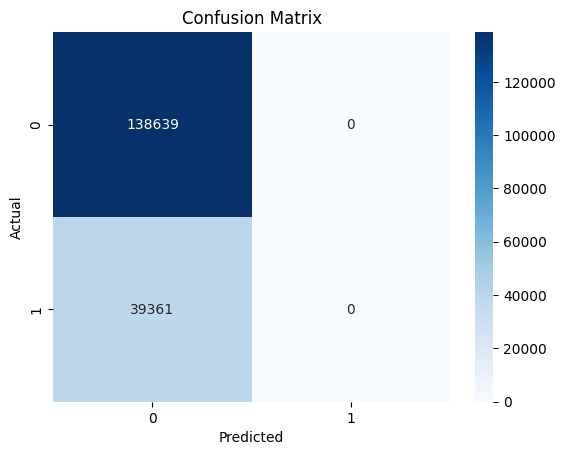

In [ ]:
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

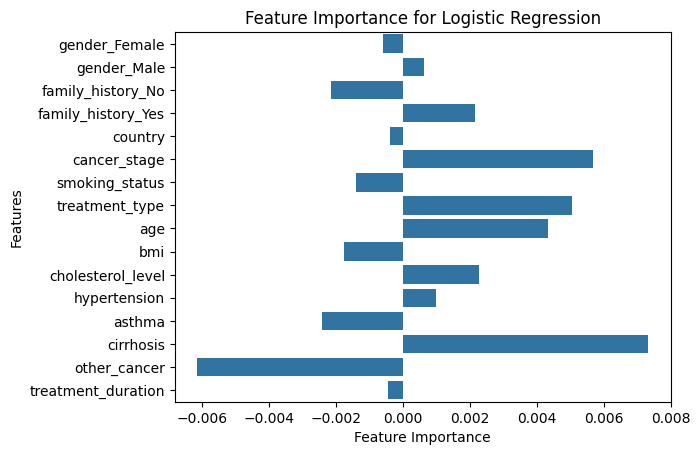

In [ ]:
feature_importance = pd.Series(log_reg.coef_[0], index=X.columns)
sns.barplot(x=feature_importance, y=feature_importance.index)
plt.xlabel('Feature Importance')
plt.ylabel('Features')
plt.title('Feature Importance for Logistic Regression')
plt.show()

## Using K-Nearest Neighbors

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier()
knn.fit(X_train_s, y_train)

y_pred = knn.predict(X_test_s)

accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

Accuracy: 0.7369550561797753


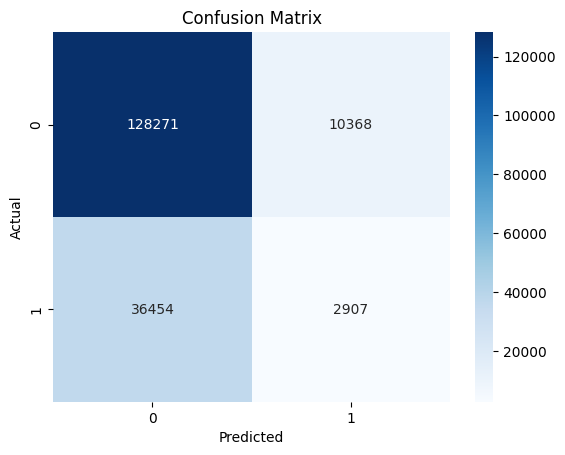

In [ ]:
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()